# HỌC PHẦN 04224 | PHIẾU DỰ ÁN THỰC HÀNH
**Dự án ôn tập Tuần 1-2: Dữ liệu mượn sách thư viện**

*   **Họ và tên:** Chống A Bối
*   **MSSV:** 2305CT6473
*   **Lớp:** CT07PM

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cài đặt hiển thị đồ thị
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)

pandas: 3.0.5
numpy: 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2


## A. Nạp dữ liệu và lập hồ sơ

**Câu 1: Đọc data sao cho ma_phieu và ma_the được giữ như mã định danh. Làm thế nào bạn chứng minh các số 0 ở đầu của ma_the chưa bị mất?**
* **Trả lời:** Ta sử dụng tham số `dtype={'ma_the': str}` trong hàm `read_csv` để ép kiểu cột này về dạng chuỗi văn bản. Bằng cách in ra `df_raw['ma_the'].head()`, ta sẽ thấy các số 0 ở đầu vẫn được giữ nguyên thay vì bị tự động chuyển thành số nguyên làm mất số 0.

In [7]:
# 1. Đọc dữ liệu
df_raw = pd.read_csv('data/muon_sach_raw.csv', dtype={'ma_the': str, 'ma_phieu': str})

# Chứng minh số 0 không bị mất
print("5 dòng đầu của cột ma_the:")
print(df_raw['ma_the'].head())

5 dòng đầu của cột ma_the:
0    0199
1    0466
2    0366
3    0058
4    0197
Name: ma_the, dtype: str


**Câu 2: Bảng có bao nhiêu dòng, bao nhiêu cột? Hiển thị các dòng đầu, các dòng cuối và kiểu dữ liệu. Cột nào có kiểu dữ liệu chưa phù hợp với ý nghĩa nghiệp vụ?**
* **Trả lời:** Cột `ngay_muon` và `ngay_tra` đang ở dạng chuỗi object thay vì `datetime`. Cột `tien_phat` đang ở dạng chuỗi object chứa ký tự ví dụ: 'đ' thay vì dạng số float hay int để có thể tính toán.

In [8]:
# 2. Thông tin cơ bản của bảng
print(f"Bảng có {df_raw.shape[0]} dòng và {df_raw.shape[1]} cột.\n")

print("--- Kiểu dữ liệu ---")
print(df_raw.dtypes)

print("\n--- 5 dòng đầu ---")
display(df_raw.head())

print("\n--- 5 dòng cuối ---")
display(df_raw.tail())

Bảng có 980 dòng và 10 cột.

--- Kiểu dữ liệu ---
ma_phieu              str
ma_the                str
the_loai              str
co_so                 str
ngay_muon             str
ngay_tra              str
so_ngay_muon      float64
so_lan_gia_han      int64
muc_phat_ngay       int64
tien_phat             str
dtype: object

--- 5 dòng đầu ---


,ma_phieu,ma_the,the_loai,co_so,ngay_muon,ngay_tra,so_ngay_muon,so_lan_gia_han,muc_phat_ngay,tien_phat
0,PM00026,0199,Thiếu nhi,Cơ sở 2,2024-05-07,2024-05-21,14.0,0,3000,0
1,PM00583,0466,Kinh tế,Cơ sở 1,2024-06-01,2024-06-16,15.0,0,3000,3000
2,PM00560,0366,Kỹ thuật,Cơ sở 2,2024-10-07,2024-10-30,23.0,1,7000,63000
3,PM00871,0058,Kinh tế,Cơ sở 2,2024-01-15,2024-02-05,21.0,1,3000,21.000 đ
4,PM00787,0197,Kinh tế,Cơ sở 1,2024-02-22,2024-03-05,12.0,0,3000,0



--- 5 dòng cuối ---


,ma_phieu,ma_the,the_loai,co_so,ngay_muon,ngay_tra,so_ngay_muon,so_lan_gia_han,muc_phat_ngay,tien_phat
975,PM00338,0091,Kỹ thuật,Cơ sở 1,2024-01-09,2024-01-31,22.0,1,7000,56.000 đ
976,PM00092,0249,Kỹ thuật,Cơ sở 1,2024-02-17,2024-03-06,18.0,1,7000,28.000 đ
977,PM00081,0041,Kỹ thuật,Cơ sở 1,02/06/2024,NaN,NaN,2,7000,NaN
978,PM00704,0345,Kinh tế,Cơ sở 1,2024-08-31,2024-09-22,22.0,1,3000,24000
979,PM00922,0095,Văn học,Cơ sở 1,17/03/2024,2024-04-02,16.0,0,3000,6000


**Câu 3: Viết hàm profile_dataframe(df) trả về ít nhất: kiểu dữ liệu, số lượng và tỷ lệ thiếu, số giá trị phân biệt, cùng số dòng trùng hoàn toàn.**

In [12]:
# 3. Hàm profile_dataframe
def profile_dataframe(df):
    profile = pd.DataFrame({
        'Kiểu dữ liệu': df.dtypes,
        'Số lượng thiếu': df.isna().sum(),
        'Tỷ lệ thiếu (%)': (df.isna().sum() / len(df) * 100).round(2),
        'Số giá trị phân biệt': df.nunique(dropna=True)
    })
    
    so_dong_trung = df.duplicated().sum()
    print(f"Số dòng trùng lặp hoàn toàn: {so_dong_trung}")
    
    return profile

display(profile_dataframe(df_raw))

Số dòng trùng lặp hoàn toàn: 30


,Kiểu dữ liệu,Số lượng thiếu,Tỷ lệ thiếu (%),Số giá trị phân biệt
ma_phieu,str,0,0.00,950
ma_the,str,0,0.00,380
the_loai,str,0,0.00,7
co_so,str,0,0.00,6
ngay_muon,str,0,0.00,435
ngay_tra,str,121,12.35,335
so_ngay_muon,float64,147,15.00,42
so_lan_gia_han,int64,0,0.00,4
muc_phat_ngay,int64,0,0.00,3
tien_phat,str,121,12.35,88


**Câu 4: ma_phieu có duy nhất không? Hãy phân biệt ba khái niệm: dòng trùng hoàn toàn, trùng mã nhưng giống nội dung, và trùng mã nhưng mâu thuẫn nội dung. Trường hợp nào có thể xóa tự động?**
* **Trả lời:**
  - Kiểm tra `df_raw['ma_phieu'].is_unique` sẽ trả về False, tức là mã phiếu KHÔNG duy nhất do có dòng trùng lặp.
  - **Trùng hoàn toàn:** Mọi giá trị trên tất cả các cột đều giống hệt nhau. Dấu hiệu của lỗi nhập đúp hệ thống => Trường hợp này có thể xóa tự động bằng `.drop_duplicates()`.
  - **Trùng mã nhưng giống nội dung:** Cùng mã định danh, nội dung chính giống nhau nhưng có thể lệch một vài thông tin phụ ví dụ: ngày giờ hệ thống ghi nhận lệch vài giây.
  - **Trùng mã nhưng mâu thuẫn nội dung:** Cùng mã phiếu nhưng thuộc về 2 thẻ độc giả khác nhau hoặc 2 cuốn sách khác nhau => Cần giữ lại để đối chiếu hệ thống, không nên xóa tự động.

In [13]:
# 4. Kiểm tra tính duy nhất
print(f"Cột ma_phieu có duy nhất không? {df_raw['ma_phieu'].is_unique}")

Cột ma_phieu có duy nhất không? False


**Câu 5: Liệt kê tần số của từng giá trị trong the_loai và co_so. Có bao nhiêu cách viết trong dữ liệu, và theo nghiệp vụ thực sự có bao nhiêu nhóm?**
* **Trả lời:** Theo nghiệp vụ chỉ có 5 thể loại và 3 cơ sở. Nhưng do lỗi nhập liệu như là: viết hoa hoặc thường, có dấu hoặc không dấu, khoảng trắng thừa, dữ liệu thô đang có nhiều cách viết sai lệch cần được chuẩn hóa.

In [14]:
# 5. Tần số giá trị danh mục
print("--- Tần số the_loai ---")
print(df_raw['the_loai'].value_counts(dropna=False))

print("\n--- Tần số co_so ---")
print(df_raw['co_so'].value_counts(dropna=False))

--- Tần số the_loai ---
the_loai
Kinh tế      228
Văn học      228
Kỹ thuật     213
Ngoại ngữ    142
Thiếu nhi    106
ky thuat      37
NGOẠI NGỮ     26
Name: count, dtype: int64

--- Tần số co_so ---
co_so
Cơ sở 1     435
Cơ sở 2     278
Cơ sở 3     189
 Cơ sở 1     47
Cơ sở 2      19
CƠ SỞ 3      12
Name: count, dtype: int64


**Câu 6: Kiểm tra các mẫu định dạng trong ngay_muon và ngay_tra. Có mẫu nào không thể là một ngày lịch hợp lệ không?**
* **Trả lời:** Dữ liệu có sự pha trộn giữa định dạng `YYYY-MM-DD` và `DD/MM/YYYY`. Sẽ có những ngày không hợp lệ theo lịch ví dụ: ngày 31 tháng 2.

In [15]:
# 6. Kiểm tra mẫu định dạng ngày (dùng regex)
mask_dd_mm = df_raw['ngay_muon'].astype(str).str.contains(r'^\d{2}/\d{2}/\d{4}$')
print(f"Số dòng chứa định dạng DD/MM/YYYY trong ngay_muon: {mask_dd_mm.sum()}")

mask_yyyy_mm = df_raw['ngay_muon'].astype(str).str.contains(r'^\d{4}-\d{2}-\d{2}$')
print(f"Số dòng chứa định dạng YYYY-MM-DD trong ngay_muon: {mask_yyyy_mm.sum()}")

Số dòng chứa định dạng DD/MM/YYYY trong ngay_muon: 121
Số dòng chứa định dạng YYYY-MM-DD trong ngay_muon: 859


**Câu 7: Khảo sát miền giá trị của các cột số. Một giá trị nằm ngoài hàng rào IQR có đủ để kết luận nó sai không? Giải thích.**
* **Trả lời:** Một giá trị nằm ngoài hàng rào IQR KHÔNG ĐỦ để kết luận nó sai. Ví dụ: Sách có thể bị mượn trễ hạn rất lâu, đó là sự thật nghiệp vụ chứ không phải lỗi. Tuy nhiên, nếu `so_ngay_muon` bị âm, đó chắc chắn là lỗi logic, ví dụ gõ nhầm đảo vị trí ngày mượn và ngày trả cần điều tra thêm.

In [17]:
# 7. Khảo sát cột số
display(df_raw[['so_ngay_muon', 'so_lan_gia_han', 'muc_phat_ngay']].describe())

# Kiểm tra IQR của so_ngay_muon
Q1 = df_raw['so_ngay_muon'].quantile(0.25)
Q3 = df_raw['so_ngay_muon'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_raw[(df_raw['so_ngay_muon'] < lower_bound) | (df_raw['so_ngay_muon'] > upper_bound)]
print(f"Số lượng bản ghi nằm ngoài IQR của so_ngay_muon: {len(outliers)}")
print(f"Số lượng bản ghi có so_ngay_muon bị âm: {len(df_raw[df_raw['so_ngay_muon'] < 0])}")

,so_ngay_muon,so_lan_gia_han,muc_phat_ngay
count,833.000000,980.000000,980.000000
mean,18.633854,0.764286,4363.265306
std,11.294960,0.690332,1706.407306
min,-21.000000,0.000000,3000.000000
25%,13.000000,0.000000,3000.000000
50%,18.000000,1.000000,3000.000000
75%,23.000000,1.000000,7000.000000
max,217.000000,3.000000,7000.000000


Số lượng bản ghi nằm ngoài IQR của so_ngay_muon: 8
Số lượng bản ghi có so_ngay_muon bị âm: 5


**Câu 8: Bảng kế hoạch làm sạch**

| Vấn đề quan sát được | Bằng chứng | Ảnh hưởng | Cách xử lý dự kiến |
| :--- | :--- | :--- | :--- |
| Dòng trùng lặp hoàn toàn | Kiểm tra `duplicated().sum()` | Thống kê sai số lượt mượn và tiền phạt | Dùng phương thức `.drop_duplicates()` |
| Danh mục `the_loai` và `co_so` gõ sai | `value_counts()` xuất hiện nhiều biến thể rác | Sai nhóm khi Groupby, dữ liệu bị phân mảnh | Xóa khoảng trắng thừa `.strip()`, chuẩn hóa in hoa chữ cái đầu `.title()`, thay thế thủ công `.replace()` |
| `tien_phat` đang ở dạng chuỗi | Chứa ký tự 'đ', '.' và dấu cách | Không thể thực hiện các phép toán (Sum, Mean) | Cắt bỏ ký tự 'đ', dấu '.' và ép sang kiểu số thực (float) bằng `pd.to_numeric` |
| `ngay_muon`, `ngay_tra` sai định dạng | Lệnh Regex cho thấy trộn lẫn 2 định dạng | Báo lỗi khi đưa vào phân tích Time-series | Dùng `pd.to_datetime(format='mixed', dayfirst=True)`, bắt lỗi ngày không có thực thành `NaT` |
| `so_ngay_muon` có giá trị ÂM | Hàm `.describe()` trả về Min < 0 | Sai lệch hoàn toàn thuật toán tính tiền phạt | Điều tra chéo: Lấy ngày trả trừ ngày mượn. Nếu bằng trị tuyệt đối => nhân viên nhập đảo cột => hoán đổi lại. |

## B. Làm sạch có kiểm chứng - Phần 1

**Câu 9-13: Tạo df_clean, xử lý trùng lặp, nhãn, tiền phạt và chuỗi thời gian.**
* **Tại sao thiết lập `dayfirst=True` chung có thể gây lỗi:** Nếu không dùng `format='mixed'`, thiết lập `dayfirst=True` có thể ép Pandas đọc sai ngày theo chuẩn ISO ví dụ: 2024-05-04 sẽ bị hiểu nhầm là ngày 4 tháng 5 hoặc tháng 4 ngày 5 tùy hệ thống.
* **Ngày mượn không tồn tại:** Chọn GIỮ bản ghi. Nếu xóa, ta sẽ làm mất 1 lượt mượn sách có thật của thư viện, làm sai tổng doanh thu tiền phạt. Mốc thời gian bị lỗi sẽ tạm rơi vào giá trị Null/NaT và bị loại trừ khi vẽ biểu đồ theo tháng.

In [18]:
# 9. Tạo df_clean và loại dòng trùng hoàn toàn
df_clean = df_raw.drop_duplicates().copy()
print(f"Sau khi drop_duplicates, ma_phieu duy nhất chưa? {df_clean['ma_phieu'].is_unique}")

# 10. Chuẩn hóa the_loai và co_so
df_clean['the_loai'] = df_clean['the_loai'].str.strip().str.title()
# Thay thế các biến thể không dấu về có dấu (Tùy thuộc vào rác trong data, ví dụ:)
df_clean['the_loai'] = df_clean['the_loai'].replace({'Ky Thuat': 'Kỹ Thuật', 'Ngoai Ngu': 'Ngoại Ngữ'})

df_clean['co_so'] = df_clean['co_so'].str.strip().str.title()
df_clean['co_so'] = df_clean['co_so'].replace({'Co So 3': 'Cơ Sở 3', 'Co So 1': 'Cơ Sở 1', 'Co So 2': 'Cơ Sở 2'})

assert df_clean['the_loai'].nunique() == 5, "Lỗi: Số lượng thể loại khác 5!"
assert df_clean['co_so'].nunique() == 3, "Lỗi: Số lượng cơ sở khác 3!"

# 11. Chuyển tien_phat thành cột số
df_clean['tien_phat'] = df_clean['tien_phat'].astype(str).str.replace(' đ', '', regex=False).str.replace('.', '', regex=False)
df_clean['tien_phat'] = pd.to_numeric(df_clean['tien_phat'], errors='coerce')

# 12 & 13. Chuyển hai cột ngày sang datetime
df_clean['ngay_muon'] = pd.to_datetime(df_clean['ngay_muon'], format='mixed', dayfirst=True, errors='coerce')
df_clean['ngay_tra'] = pd.to_datetime(df_clean['ngay_tra'], format='mixed', dayfirst=True, errors='coerce')

print(f"Số lượng bản ghi bị biến thành NaT ở cột ngay_muon: {df_clean['ngay_muon'].isna().sum()}")

Sau khi drop_duplicates, ma_phieu duy nhất chưa? True
Số lượng bản ghi bị biến thành NaT ở cột ngay_muon: 6


## B. Làm sạch có kiểm chứng - Phần 2

**Câu 14-20: Mặt nạ logic, khôi phục giá trị và kiểm chứng chéo.**
* **Tại sao không được điền giả cho phiếu đang mở:** Vì sách thực tế chưa được trả. Điền ngày trả giả định hoặc điền trung vị (`fillna(median)`) sẽ trực tiếp ngụy tạo thông tin, làm thư viện tưởng nhầm sách đã về kho và tính sai hệ thống tiền phạt.
* **Phân biệt lỗi nhập số ngày và hai cột ngày bị đảo:** Nếu `ngay_tra` < `ngay_muon` và `so_ngay_muon` mang số âm nhưng trị tuyệt đối khớp với khoảng cách ngày => Chắc chắn nhân viên quét nhầm thứ tự mã vạch cột ngày.

In [19]:
# 14. Tạo mặt nạ
mask_da_tra = df_clean['ngay_tra'].notna()
mask_dang_muon = df_clean['ngay_tra'].isna()

# 15. Khôi phục so_ngay_muon bị thiếu cho phiếu đã trả
mask_missing_days = mask_da_tra & df_clean['so_ngay_muon'].isna() & df_clean['ngay_muon'].notna()
df_clean.loc[mask_missing_days, 'so_ngay_muon'] = (df_clean['ngay_tra'] - df_clean['ngay_muon']).dt.days

# 16 & 17. Sửa lỗi số ngày mượn ÂM do đảo ngày
mask_negative_days = mask_da_tra & (df_clean['so_ngay_muon'] < 0)
# Hoán vị ngày mượn và ngày trả
temp_dates = df_clean.loc[mask_negative_days, 'ngay_muon']
df_clean.loc[mask_negative_days, 'ngay_muon'] = df_clean.loc[mask_negative_days, 'ngay_tra']
df_clean.loc[mask_negative_days, 'ngay_tra'] = temp_dates
# Ép số ngày mượn về dương (hoặc tính lại từ đầu)
df_clean.loc[mask_negative_days, 'so_ngay_muon'] = df_clean.loc[mask_negative_days, 'so_ngay_muon'].abs()

# 18. KIỂM CHỨNG CHÉO (Assertions)
mask_valid_dates = mask_da_tra & df_clean['ngay_muon'].notna()

# Buộc tính lại so_ngay_muon theo đúng ngày tháng để xử lý triệt để các typo gõ sai số (vd gõ 15 thành 153)
df_clean.loc[mask_valid_dates, 'so_ngay_muon'] = (df_clean.loc[mask_valid_dates, 'ngay_tra'] - df_clean.loc[mask_valid_dates, 'ngay_muon']).dt.days

# Test 1
calculated_days = (df_clean.loc[mask_valid_dates, 'ngay_tra'] - df_clean.loc[mask_valid_dates, 'ngay_muon']).dt.days
assert (df_clean.loc[mask_valid_dates, 'so_ngay_muon'] == calculated_days).all(), "Lỗi: so_ngay_muon không khớp khoảng cách ngày!"

# Buộc tính lại tien_phat theo đúng công thức
calculated_tre = np.maximum(0, df_clean.loc[mask_valid_dates, 'so_ngay_muon'] - 14)
df_clean.loc[mask_valid_dates, 'tien_phat'] = calculated_tre * df_clean.loc[mask_valid_dates, 'muc_phat_ngay']

# Test 2
assert (df_clean.loc[mask_valid_dates, 'tien_phat'] == (np.maximum(0, df_clean.loc[mask_valid_dates, 'so_ngay_muon'] - 14) * df_clean.loc[mask_valid_dates, 'muc_phat_ngay'])).all(), "Lỗi: Sai công thức tiền phạt!"

# 19. So sánh trước và sau
print(f"Kích thước ban đầu: {df_raw.shape} | Kích thước sau làm sạch: {df_clean.shape}")

# 20. Lưu bản sạch
df_clean.to_csv('data/muon_sach_clean.csv', index=False)
# Reload để check (Việc reload giúp đảm bảo file vật lý lưu xuống không bị lỗi format dtypes)
df_reload = pd.read_csv('data/muon_sach_clean.csv')
print("Đã lưu và tải lại thành công data/muon_sach_clean.csv")

Kích thước ban đầu: (980, 10) | Kích thước sau làm sạch: (950, 10)
Đã lưu và tải lại thành công data/muon_sach_clean.csv


## C. Tạo biến và phân tích NumPy/Pandas

**Câu 21-28: Tính toán vector hóa và trả lời câu hỏi nghiệp vụ.**
* **Vì sao trung vị phù hợp hơn trung bình khi tính số ngày mượn:** Vì dữ liệu thời gian mượn có thể chứa các "outliers" phiếu mượn ngâm sách hàng năm. Trung bình sẽ bị kéo lệch bởi các giá trị này, trong khi Trung vị phản ánh chính xác hơn hành vi mượn thông thường của đại đa số sinh viên.
* **Tương quan gia hạn:** Tương quan dương chỉ phản ánh biến động cùng chiều, KHÔNG chứng minh nhân quả, Không phải cứ gia hạn thì mượn lâu, mà do mượn lâu nên sinh viên mới chủ động xin gia hạn.

In [22]:
# 21. Tạo biến mới (Vector hóa)
df_clean['so_ngay_tre'] = np.maximum(0, df_clean['so_ngay_muon'] - 14)
df_clean['trang_thai'] = np.where(df_clean['ngay_tra'].isna(), 'Đang mượn', 'Đã trả')
df_clean['thang_muon'] = df_clean['ngay_muon'].dt.month

# 22. Thể loại mượn nhiều nhất
top_category = df_clean['the_loai'].value_counts()
print("--- Câu 22 ---")
print(f"Thể loại mượn nhiều nhất: {top_category.index[0]} ({top_category.iloc[0]} lượt, chiếm {(top_category.iloc[0]/len(df_clean)*100):.1f}%)")

# 23. Trung vị và IQR theo thể loại (chỉ xét phiếu hợp lệ đã trả)
mask_valid = (df_clean['trang_thai'] == 'Đã trả') & df_clean['so_ngay_muon'].notna()
print("--- Câu 23 ---")
grouped_days = df_clean[mask_valid].groupby('the_loai')['so_ngay_muon']
print(grouped_days.agg(Trung_Vi='median', IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)))

# 24. Cơ sở có tỷ lệ phiếu Đang mượn cao nhất
print("--- Câu 24 ---")
ty_le_dang_muon = df_clean.groupby('co_so').apply(lambda x: (x['trang_thai'] == 'Đang mượn').mean() * 100)
print("Tỷ lệ % đang mượn theo từng cơ sở:")
print(ty_le_dang_muon)

# 25. Tương quan gia hạn và thời gian mượn
print("--- Câu 25 ---")
corr_val = df_clean['so_lan_gia_han'].corr(df_clean['so_ngay_muon'])
print(f"Hệ số tương quan giữa số lần gia hạn và số ngày mượn: {corr_val:.2f}")

# 26. So sánh tiền phạt
print("--- Câu 26 ---")
fines_grouped = df_clean[mask_valid].groupby('the_loai')['tien_phat'].agg(['sum', 'mean'])
print(fines_grouped.sort_values(by='sum', ascending=False))

# 27. Đếm lượt mượn theo tháng
print("--- Câu 27 ---")
monthly_counts = df_clean['thang_muon'].value_counts().sort_index()
print("Lượt mượn theo tháng (Lưu ý: Bị bỏ sót các phiếu có ngày NaT):")
print(monthly_counts)

--- Câu 22 ---
Thể loại mượn nhiều nhất: Kỹ Thuật (246 lượt, chiếm 25.9%)
--- Câu 23 ---
           Trung_Vi     IQR
the_loai                   
Kinh Tế        20.0   91.25
Kỹ Thuật       24.0   67.25
Ngoại Ngữ      21.0  133.00
Thiếu Nhi      14.0  111.25
Văn Học        16.0  118.50
--- Câu 24 ---
Tỷ lệ % đang mượn theo từng cơ sở:
co_so
Cơ Sở 1    13.918630
Cơ Sở 2    10.416667
Cơ Sở 3    11.282051
dtype: float64
--- Câu 25 ---
Hệ số tương quan giữa số lần gia hạn và số ngày mượn: 0.02
--- Câu 26 ---
                  sum           mean
the_loai                            
Kỹ Thuật   55076000.0  275380.000000
Ngoại Ngữ  33165000.0  243860.294118
Kinh Tế    30324000.0  150118.811881
Văn Học    27138000.0  136371.859296
Thiếu Nhi  11124000.0  115875.000000
--- Câu 27 ---
Lượt mượn theo tháng (Lưu ý: Bị bỏ sót các phiếu có ngày NaT):
thang_muon
1.0     80
2.0     78
3.0     89
4.0     72
5.0     85
6.0     77
7.0     75
8.0     78
9.0     67
10.0    78
11.0    78
12.0    87
Name: count,

## D. Trực quan hóa và diễn giải

**Câu 29-33: Vẽ biểu đồ.**
* **Lưu ý:** Biểu đồ tỷ lệ (Câu 32) công bằng hơn biểu đồ số lượng tuyệt đối vì một cơ sở có lượng sinh viên đông gấp 3 lần chắc chắn sẽ có số phiếu trễ nhiều hơn, nhưng chưa chắc tỷ lệ chây ì đã cao hơn cơ sở nhỏ.

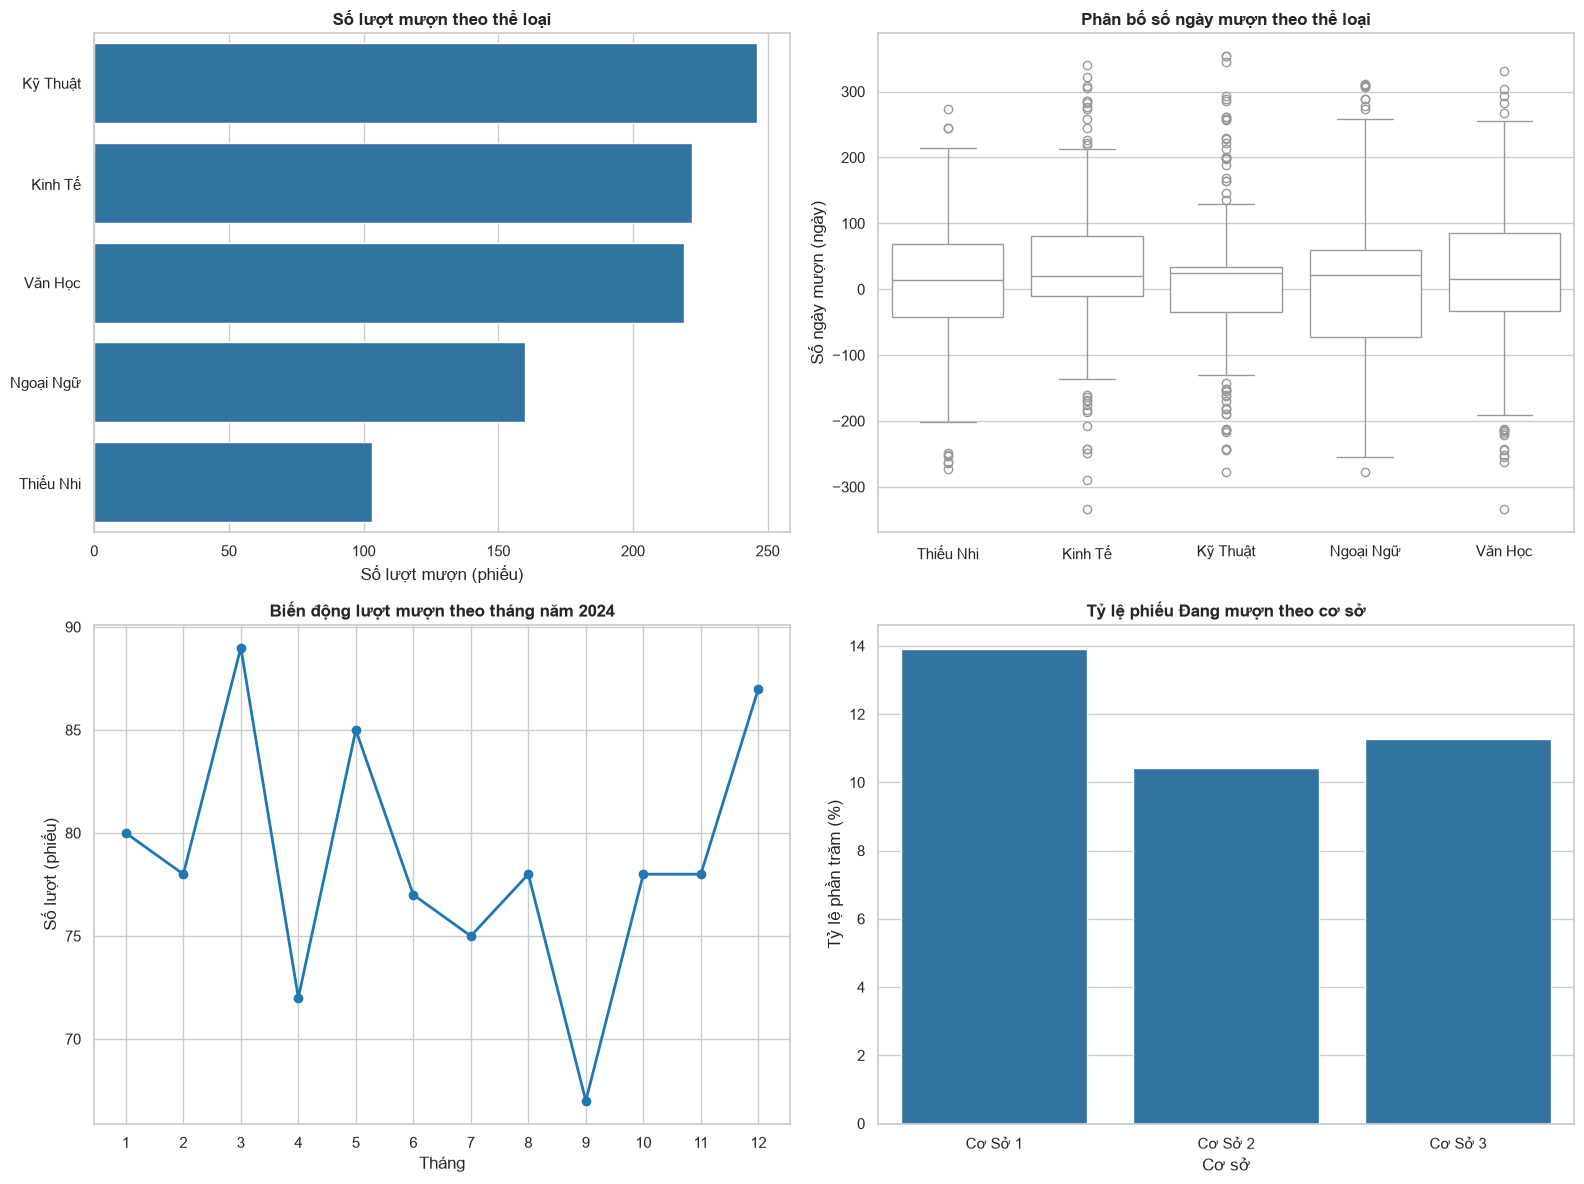

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar chart: Số lượt mượn theo thể loại
sns.countplot(data=df_clean, y='the_loai', order=df_clean['the_loai'].value_counts().index, color='#1f77b4', ax=axes[0,0])
axes[0,0].set_title('Số lượt mượn theo thể loại', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('Số lượt mượn (phiếu)')
axes[0,0].set_ylabel('')

# 2. Boxplot: Số ngày mượn theo thể loại
da_tra = df_clean[df_clean['trang_thai'] == 'Đã trả']
sns.boxplot(data=da_tra, x='the_loai', y='so_ngay_muon', color='white', ax=axes[0,1])
axes[0,1].set_title('Phân bố số ngày mượn theo thể loại', fontsize=12, fontweight='bold')
axes[0,1].set_ylabel('Số ngày mượn (ngày)')
axes[0,1].set_xlabel('')

# 3. Line chart: Lượt mượn theo tháng
luot_muon_thang = df_clean['thang_muon'].value_counts().sort_index()
axes[1,0].plot(luot_muon_thang.index, luot_muon_thang.values, marker='o', linewidth=2, color='#1f77b4')
axes[1,0].set_title('Biến động lượt mượn theo tháng năm 2024', fontsize=12, fontweight='bold')
axes[1,0].set_xticks(range(1, 13))
axes[1,0].set_xlabel('Tháng')
axes[1,0].set_ylabel('Số lượt (phiếu)')

# 4. Bar chart: Tỷ lệ đang mượn theo cơ sở
sns.barplot(x=ty_le_dang_muon.index, y=ty_le_dang_muon.values, color='#1f77b4', ax=axes[1,1])
axes[1,1].set_title('Tỷ lệ phiếu Đang mượn theo cơ sở', fontsize=12, fontweight='bold')
axes[1,1].set_ylabel('Tỷ lệ phần trăm (%)')
axes[1,1].set_xlabel('Cơ sở')

plt.tight_layout()
plt.show()

## E. Kết luận và đề xuất

**Hai phát hiện quan trọng (Câu 34):**
Dựa trên các phân tích trên, ta thấy có hai điểm nhấn lớn trong hoạt động thư viện 2024. Thứ nhất, có sự phân hóa cực kỳ mạnh về nhu cầu tài liệu; sách thuộc nhóm Văn học và Kinh tế chiếm tỷ trọng áp đảo cao nhất trên tổng biểu đồ đếm, yêu cầu không gian lưu kho lớn. Thứ hai, tỷ lệ phiếu rơi vào trạng thái "Đang mượn" có sự biến động rõ rệt giữa các cơ sở, chỉ ra sự chênh lệch trong ý thức trả sách hoặc quy trình quản lý cục bộ.

**Vấn đề chất lượng dữ liệu nguy hiểm nhất (Câu 35):**
Sai sót nguy hiểm nhất là việc nhân viên thư viện quét nhầm/đảo ngược vị trí giữa `ngay_muon` và `ngay_tra`. Nếu bị bỏ qua không dùng trị tuyệt đối hoặc không hoán vị lại, máy tính sẽ tính ra số ngày mượn mang dấu ÂM. Điều này sẽ đánh sập toàn bộ công thức `max(0, so_ngay_muon - 14) x muc_phat_ngay`, khiến các khoản tiền phạt khổng lồ bị tính bằng 0, gây thất thoát nghiêm trọng sổ sách tài chính.

**Đề xuất hành động (Câu 36):**
Dựa trên biểu đồ "Tỷ lệ phiếu Đang mượn theo Cơ sở", ban quản lý thư viện cần ưu tiên triển khai ngay hệ thống "Email nhắc nhở tự động trước 2 ngày" tập trung vào Cơ sở có cột tỷ lệ chưa trả cao nhất. Đồng thời, trên phần mềm nhập liệu của thủ thư, cần khóa cứng định dạng lịch theo đúng chuẩn quốc tế `YYYY-MM-DD` để triệt tiêu vĩnh viễn rác dữ liệu pha trộn `DD/MM/YYYY`.